Enter pH(4-10):  7
Enter Temperature(10-40):  23
Enter Initial Population(100-1,000,000):  8000
Enter Nutrient Available(1-10):  6


Time: 0 hours | Population: 9781.13
Time: 1 hours | Population: 9781.84
Time: 2 hours | Population: 9782.54
Time: 3 hours | Population: 9783.24
Time: 4 hours | Population: 9783.95
Time: 5 hours | Population: 9784.65
Time: 6 hours | Population: 9785.35
Time: 7 hours | Population: 9786.06
Time: 8 hours | Population: 9786.76
Time: 9 hours | Population: 9787.47
Time: 10 hours | Population: 9788.17
Time: 11 hours | Population: 9788.88
Time: 12 hours | Population: 9789.58
Time: 13 hours | Population: 9790.29
Time: 14 hours | Population: 9790.99
Time: 15 hours | Population: 9791.70
Time: 16 hours | Population: 9792.40
Time: 17 hours | Population: 9793.11
Time: 18 hours | Population: 9793.82
Time: 19 hours | Population: 9794.52
Time: 20 hours | Population: 9795.23
Time: 21 hours | Population: 9795.93
Time: 22 hours | Population: 9796.64
Time: 23 hours | Population: 9797.35
Time: 24 hours | Population: 9798.06
Time: 25 hours | Population: 9798.76
Time: 26 hours | Population: 9799.47
Time: 27 ho

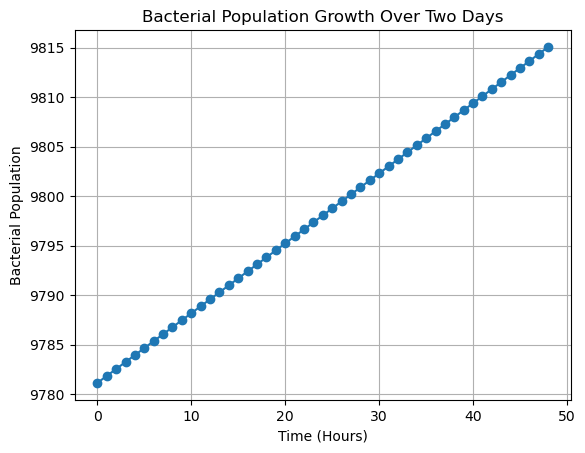

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
KS = 3.5 ## Half saturation constant
UREF = 3.6 #Reference growth rate
OPH = 7.1 #Optimal pH
userPH = float(input("Enter pH(4-10): ")) #user input for pH
OT = 27 # Optimal Temp
userTemp = float(input("Enter Temperature(10-40): ")) #user input for temp
tempConst = 0.02773 #approximation from optimal temp and diff at 50 degrees
deltaT = abs(userTemp - OT)
lagTime = 1.5 + 4.5*(deltaT)
pHSens = 0.7 # pH sensitivity constant, decreases which is why it is negative
initialPop = float(input("Enter Initial Population(100-1,000,000): ")) #user input for initial population
nutrientAvail = float(input("Enter Nutrient Available(1-10): ")) #user input for nutrient availability
growthConstant = 0.0; #growth constant in response to nutrient availability
if (nutrientAvail >= 1 and nutrientAvail <= 5):
	growthConstant = 2 + 0.5*(nutrientAvail - 1)
elif(nutrientAvail > 5 and nutrientAvail <= 10):
    growthConstant = 4 + 0.4*(nutrientAvail - 5)
a = initialPop*(growthConstant - 1) #max increase in bacterial population above the initial population
fPH = np.exp(-pHSens*(userPH - OPH)**2) #effect of pH on the growth rate
fT = np.exp(-tempConst * (userTemp - OT)**2) #effect of the temp on the growth rate
fS =  nutrientAvail / (KS + nutrientAvail) #effect of the nutrient availability on the growth rate
uMax = (UREF)*fPH*fT*fS #max growth rate given the bounds
times = np.arange(0, 49, 1) #49 points from 0-48
population_values = []
for t in times:
    x = (uMax * np.e * (lagTime - t)) / a + 1 #bacterial population at a specific time
    N = initialPop + a*(np.exp(-np.exp(x))) #population change in response to all the conditions at a specific time
    population_values.append(N)
#times used 0, 2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24
#keep different points to be able to plot on graph
for t, population in zip(times, population_values):
    print(f"Time: {t} hours | Population: {population:.2f}")
df = pd.DataFrame({
    "Time (Hours)": times,
    "Population": population_values
})
plt.plot(times, population_values, marker='o', linestyle='-', color='teal', linewidth=4)
plt.title("Bacterial Population Growth Over Two Days",fontsize=16, fontweight='bold')
plt.xlabel("Time (Hours)", fontsize=11)
plt.ylabel("Bacterial Population", fontsize=11)
plt.gca().set_facecolor('honeydew')
plt.grid(True)
plt.show()